# CST 627 Week 7 — LoRA Rank Ablation
This notebook is only a launcher. The scripts and YAML config are the source of truth, so notebook cell order cannot silently change the experiment. Select a GPU runtime before continuing.

In [1]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/cst627-week7-lora-ablation')
assert (PROJECT_DIR / 'requirements.txt').exists(), f'Project folder not found at {PROJECT_DIR}'
%cd {PROJECT_DIR}
!nvidia-smi
!python -m pip install -r requirements.txt
!python -m unittest discover -s tests -v

Mounted at /content/drive
/content/drive/MyDrive/cst627-week7-lora-ablation
Thu Oct 22 21:21:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                     

## Engineering smoke test
The following values are not confirmatory study results. Use the timing artifact to make the pre-registered seed-count decision.

In [2]:
!python run_ablation.py --config configs/ablation.yaml --mode all --smoke
import json
from pathlib import Path
print(json.dumps(json.loads(Path('artifacts/smoke/benchmark.json').read_text()), indent=2))

Pretraining complete in 4.28s on cuda
rank=4 seed=101 engineering result: MAPE=10.911% time=0.12s
rank=8 seed=101 engineering result: MAPE=10.850% time=0.07s
rank=16 seed=101 engineering result: MAPE=10.777% time=0.07s
Aggregated 3 runs into /content/drive/MyDrive/cst627-week7-lora-ablation/artifacts/smoke/results
{
  "mode": "all",
  "smoke": true,
  "wall_clock_seconds": 7.958821407999949,
  "pretrain_seconds": 4.279121039000074,
  "device": "cuda",
  "completed_runs": 3
}


In [3]:
from copy import deepcopy
from pathlib import Path
import yaml

base = yaml.safe_load(Path("configs/ablation.yaml").read_text())
bench = deepcopy(base)

bench["project"]["output_dir"] = "artifacts/timing_benchmark"
bench["data"]["path"] = "artifacts/timing_benchmark/data/synthetic_demand.npz"
bench["data"]["metadata_path"] = "artifacts/timing_benchmark/data/metadata.json"
bench["data"]["generation_seed"] = 62708
bench["pretraining"]["checkpoint"] = "artifacts/timing_benchmark/checkpoints/shared_backbone.pt"
bench["pretraining"]["epochs"] = 1
bench["adaptation"]["epochs"] = 1
bench["model"]["ranks"] = [8]
bench["reproducibility"]["study_seeds"] = [909]

Path("configs/timing_benchmark.yaml").write_text(
    yaml.safe_dump(bench, sort_keys=False)
)

1673

In [4]:
!python run_ablation.py --config configs/timing_benchmark.yaml --mode all

Generated dataset: /content/drive/MyDrive/cst627-week7-lora-ablation/artifacts/timing_benchmark/data/synthetic_demand.npz (sha256=5ec5e4fa0634248436f6ae9a6f71ded45bdb4dcec26e7c76f7f73abb906264d5)
Pretraining complete in 8.59s on cuda
rank=8 seed=909 engineering result: MAPE=3.350% time=1.61s
Aggregated 1 runs into /content/drive/MyDrive/cst627-week7-lora-ablation/artifacts/timing_benchmark/results


In [5]:
from pathlib import Path
import hashlib

smoke_file = Path("artifacts/smoke/benchmark.json")
smoke_sha = hashlib.sha256(smoke_file.read_bytes()).hexdigest()

decision = f"""# Seed-count decision record

- Colab date: October 22, 2026
- GPU model: NVIDIA Tesla T4
- Smoke benchmark artifact SHA-256: {smoke_sha}
- Representative benchmark generation seed: 62708
- Representative non-study adaptation seed: 909
- One-epoch shared pretraining time: 8.59 seconds
- Projected eight-epoch shared pretraining time: 68.72 seconds
- One-epoch adaptation time: 1.61 seconds
- Projected ten-epoch adaptation time per run: 16.10 seconds
- Projected total for 9 runs: 3.56 minutes
- Projected total for 15 runs: 5.17 minutes
- 80% budget threshold: 144 minutes
- Selected seed count: 5

Five seeds were selected because the full-size, full-architecture timing
benchmark projected approximately 5.17 minutes for shared pretraining plus
15 adaptation runs. This is comfortably below the preregistered 144-minute
limit. The timing benchmark used a separate dataset-generation seed and a
non-study adaptation seed, so it is not included in confirmatory results.
"""

Path("SEED_DECISION.md").write_text(decision)
print(decision)

# Seed-count decision record

- Colab date: October 22, 2026
- GPU model: NVIDIA Tesla T4
- Smoke benchmark artifact SHA-256: 7380a61fc8069dc16720663d4f97153090624bd4b84b4fe1e8681c5043f4c5e8
- Representative benchmark generation seed: 62708
- Representative non-study adaptation seed: 909
- One-epoch shared pretraining time: 8.59 seconds
- Projected eight-epoch shared pretraining time: 68.72 seconds
- One-epoch adaptation time: 1.61 seconds
- Projected ten-epoch adaptation time per run: 16.10 seconds
- Projected total for 9 runs: 3.56 minutes
- Projected total for 15 runs: 5.17 minutes
- 80% budget threshold: 144 minutes
- Selected seed count: 5

Five seeds were selected because the full-size, full-architecture timing
benchmark projected approximately 5.17 minutes for shared pretraining plus
15 adaptation runs. This is comfortably below the preregistered 144-minute
limit. The timing benchmark used a separate dataset-generation seed and a
non-study adaptation seed, so it is not included 

In [6]:
!bash scripts/run_colab.sh 5

Pretraining complete in 53.82s on cuda
rank=4 seed=101 engineering result: MAPE=3.293% time=14.06s
rank=4 seed=202 engineering result: MAPE=3.186% time=14.30s
rank=4 seed=303 engineering result: MAPE=3.246% time=13.96s
rank=4 seed=404 engineering result: MAPE=3.235% time=14.08s
rank=4 seed=505 engineering result: MAPE=3.237% time=13.93s
rank=8 seed=101 engineering result: MAPE=3.314% time=14.16s
rank=8 seed=202 engineering result: MAPE=3.185% time=13.91s
rank=8 seed=303 engineering result: MAPE=3.260% time=13.85s
rank=8 seed=404 engineering result: MAPE=3.233% time=13.58s
rank=8 seed=505 engineering result: MAPE=3.251% time=13.63s
rank=16 seed=101 engineering result: MAPE=3.333% time=13.75s
rank=16 seed=202 engineering result: MAPE=3.182% time=13.78s
rank=16 seed=303 engineering result: MAPE=3.288% time=13.79s
rank=16 seed=404 engineering result: MAPE=3.239% time=13.75s
rank=16 seed=505 engineering result: MAPE=3.292% time=14.05s
Aggregated 15 runs into /content/drive/MyDrive/cst627-we

## Stop and record the seed decision
Complete `SEED_DECISION.md`. Choose 5 only if the projected shared pretraining plus 15 adaptations is at most 144 minutes; otherwise choose 3. Do this before the next cell.

In [7]:
SEEDS = 3  # Change to 5 only if the preregistered benchmark rule permits.
assert SEEDS in (3, 5)
!bash scripts/run_colab.sh {SEEDS}

Skipping existing rank4_seed101.json
Skipping existing rank4_seed202.json
Skipping existing rank4_seed303.json
Skipping existing rank8_seed101.json
Skipping existing rank8_seed202.json
Skipping existing rank8_seed303.json
Skipping existing rank16_seed101.json
Skipping existing rank16_seed202.json
Skipping existing rank16_seed303.json
Aggregated 15 runs into /content/drive/MyDrive/cst627-week7-lora-ablation/artifacts/results


,rank,seed,mae_kw,rmse_kw,mape_percent,training_seconds,evaluation_seconds,adaptation_and_evaluation_seconds,peak_gpu_memory_mb,trainable_parameters,device
0,16,101,5.983851,7.561022,3.333324,13.746531,0.127394,13.874124,124.213867,8192,cuda
1,16,202,5.699342,7.177981,3.182487,13.783069,0.121701,13.904963,124.213867,8192,cuda
2,16,303,5.898799,7.443821,3.288270,13.790692,0.113154,13.904038,124.213867,8192,cuda
3,16,404,5.815825,7.325392,3.239138,13.753030,0.113091,13.866292,124.213867,8192,cuda
4,16,505,5.921008,7.467136,3.291523,14.048974,0.117613,14.166768,124.213867,8192,cuda
5,4,101,5.912443,7.464165,3.293142,14.056314,0.124689,14.181196,123.018555,2048,cuda
6,4,202,5.706184,7.185298,3.186014,14.303362,0.116061,14.419600,123.018555,2048,cuda
7,4,303,5.822848,7.343297,3.246164,13.958319,0.116648,14.075150,123.018555,2048,cuda
8,4,404,5.803086,7.315402,3.235173,14.077886,0.120455,14.198532,123.018555,2048,cuda
9,4,505,5.808149,7.326874,3.237467,13.933856,0.135134,14.069171,123.018555,2048,cuda


,rank,n_seeds,mean_mape_percent,std_mape_percent,min_mape_percent,max_mape_percent,mean_training_seconds,mean_run_seconds,mean_peak_gpu_memory_mb
0,4,5,3.239592,0.038097,3.186014,3.293142,14.065947,14.188730,123.018555
1,8,5,3.248744,0.046637,3.185382,3.314337,13.826256,13.943216,123.416992
2,16,5,3.266949,0.057817,3.182487,3.333324,13.824459,13.943237,124.213867


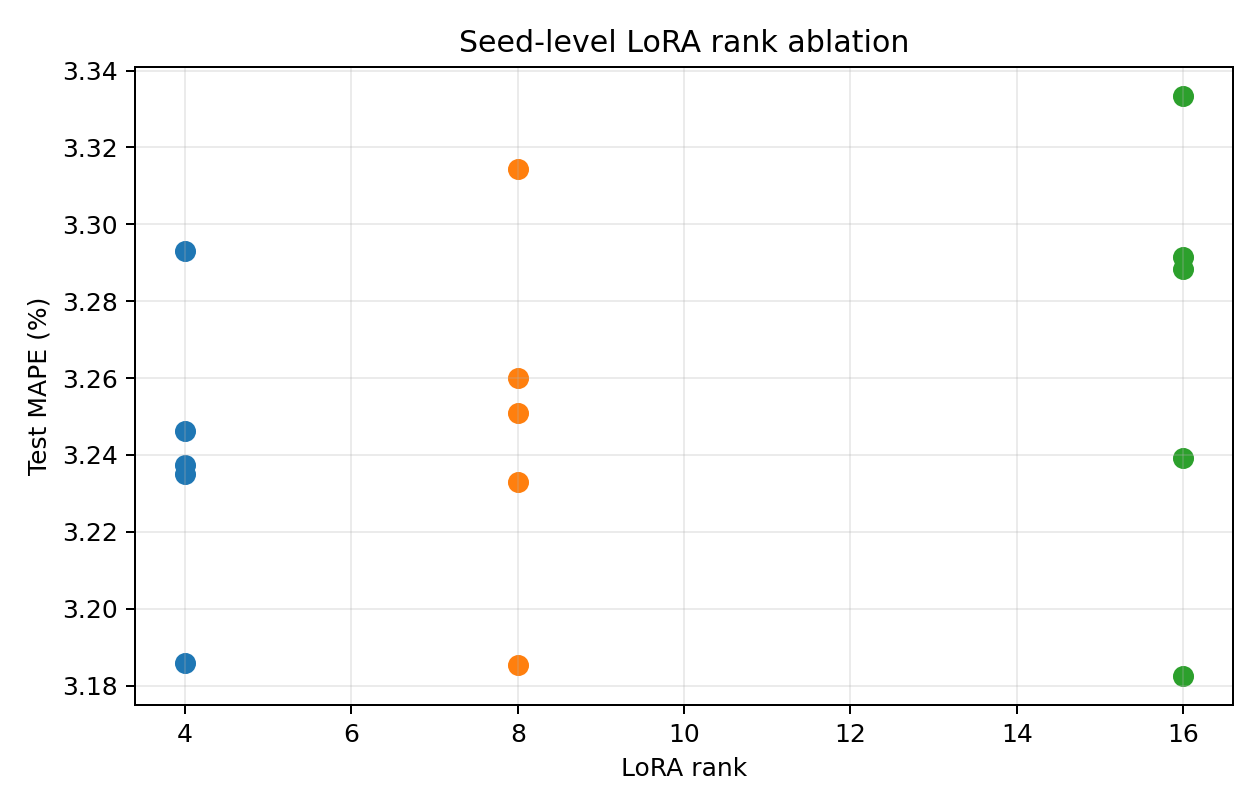

In [8]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv('artifacts/results/seed_level_results.csv'))
display(pd.read_csv('artifacts/results/summary_by_rank.csv'))
display(Image('artifacts/plots/seed_level_mape.png'))